# 06 · Ensamble de trayectorias y estadística

Una sola trayectoria no caracteriza un proceso estocástico. Aquí ejecutamos un conjunto de motores virtuales independientes y analizamos distribuciones de resultados.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.simulation.ensemble import run_ensemble
from protein_motor_sim.analysis.statistics import summarize_trajectories

motor = Kinesin1()
environment = Environment(atp_concentration=1.0e-3, temperature_K=310.0)
ensemble = run_ensemble(
    GillespieSimulator(), motor, environment,
    t_max=0.5, n_runs=100, seed=12345,
)
summary = summarize_trajectories(ensemble.trajectories)
print(summary)

EnsembleStatistics(mean_velocity_nm_s=343.9315850209267, std_velocity_nm_s=61.07608424149934, mean_run_length_nm=162.52399999999997, std_run_length_nm=37.35741409518043, number_of_trajectories=100)


## 1. Distribución de velocidades

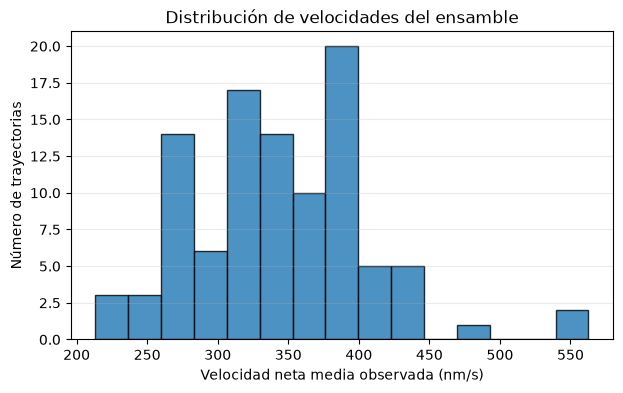

In [3]:
velocities = np.array([t.mean_velocity_nm_s for t in ensemble.trajectories])
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(velocities, bins=15, edgecolor="black", alpha=0.8)
ax.set_xlabel("Velocidad neta media observada (nm/s)")
ax.set_ylabel("Número de trayectorias")
ax.set_title("Distribución de velocidades del ensamble")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 2. Distribución de desplazamientos observados

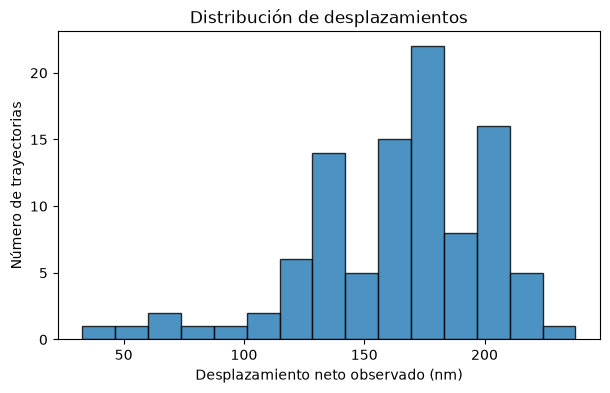

In [4]:
displacements = np.array([t.displacement_nm for t in ensemble.trajectories])
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(displacements, bins=15, edgecolor="black", alpha=0.8)
ax.set_xlabel("Desplazamiento neto observado (nm)")
ax.set_ylabel("Número de trayectorias")
ax.set_title("Distribución de desplazamientos")
plt.show()

## 3. Frecuencia de desprendimiento

In [5]:
detached = [t.final_state == "detached" for t in ensemble.trajectories]
probability_detached = np.mean(detached)
print(f"Fracción que terminó desprendida antes de t_max: {probability_detached:.3f}")
print(f"Número de trayectorias: {len(detached)}")

Fracción que terminó desprendida antes de t_max: 0.090
Número de trayectorias: 100


**Nota estadística:** una trayectoria que no se desprende durante la ventana `t_max` está censurada a la derecha. No se debe tratar su desplazamiento observado como una longitud completa de recorrido. Para estimar una longitud de recorrido física tendremos que analizar explícitamente los tiempos de desprendimiento y los datos censurados.